# 06 — Model Evaluation & Optimization: Dual-Head Siamese U-Net

## Objective

This notebook evaluates and optimizes the trained **Dual-Head Siamese U-Net** on the untouched test split (933 satellite tiles).

### Analysis & Optimization Pipeline:
1. **Checkpoint Verification:** Load best trained weights (`checkpoints/dual_head_siamese_best.pth`).
2. **Standard Evaluation:** Baseline inference at threshold 0.50.
3. **Threshold Calibration:** Fine-tuning localization decision boundary ($	au \in [0.35, 0.50]$) to balance precision and recall.
4. **Test-Time Augmentation (TTA):** Multi-angle inference averaging (original, horizontal flip, vertical flip) to eliminate edge jitter.
5. **Class-Wise Breakdown & Error Diagnostics:** IoU, F1, Precision, Recall across all 5 classes.
6. **Side-by-Side Visual Inspection:** High-resolution qualitative prediction overlays across diverse disaster events.



In [16]:
# ============================================================
# 1. IMPORTS AND ENVIRONMENT SETUP
# ============================================================

import sys
from pathlib import Path
import importlib
import json
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import src.model
importlib.reload(src.model)

from src.config import (
    DEVICE,
    USE_AMP,
    CLASS_MAPPING_5,
    NUM_TOTAL_CLASSES,
    CHECKPOINT_ROOT,
    OUTPUT_ROOT,
)
from src.dataset import get_dataloaders
from src.model import DualHeadSiameseUNet
from src.metrics import calculate_metrics_from_confusion, compute_confusion_matrix
from src.evaluate import plot_confusion_matrix, plot_visual_samples

print(f"Device: {DEVICE}")


Device: cuda


In [17]:
# ============================================================
# 2. LOAD TRAINED MODEL CHECKPOINT
# ============================================================

import importlib
import src.model
importlib.reload(src.model)
from src.model import DualHeadSiameseUNet

checkpoint_path = CHECKPOINT_ROOT / "dual_head_siamese_best.pth"
if not checkpoint_path.exists():
    checkpoint_path = CHECKPOINT_ROOT / "dual_head_siamese_latest.pth"

assert checkpoint_path.exists(), f"No checkpoint found at {checkpoint_path}!"

print(f"Loading checkpoint: {checkpoint_path}")
checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=False)

model = DualHeadSiameseUNet(pretrained=False).to(DEVICE)
state_dict = checkpoint["model_state_dict"] if "model_state_dict" in checkpoint else checkpoint
model.load_state_dict(state_dict)
model.eval()

print("Model successfully loaded in evaluation mode.")
if "best_score" in checkpoint:
    print(f"Trained Checkpoint Best Score: {checkpoint['best_score']:.4f}")


Loading checkpoint: D:\ML_Project\checkpoints\dual_head_siamese_best.pth
Model successfully loaded in evaluation mode.
Trained Checkpoint Best Score: 0.6625


In [18]:
# ============================================================
# 3. TEST DATASET INITIALIZATION
# ============================================================

_, hold_loader, test_loader = get_dataloaders()
print(f"Holdout tiles: {len(hold_loader.dataset)} | Test tiles: {len(test_loader.dataset)}")



Holdout tiles: 933 | Test tiles: 933


In [19]:
# ============================================================
# 4. RUN TEST EVALUATION WITH TEST-TIME AUGMENTATION (TTA)
# ============================================================

# Ensure predict_tta is bound even if kernel wasn't restarted
if not hasattr(model, "predict_tta"):
    import importlib
    import src.model
    importlib.reload(src.model)
    from src.model import DualHeadSiameseUNet
    model.__class__ = DualHeadSiameseUNet

# Calibrated localization threshold from holdout sweep (0.35)
OPTIMAL_LOC_THRESHOLD = 0.35

confusion_std = np.zeros((NUM_TOTAL_CLASSES, NUM_TOTAL_CLASSES), dtype=np.int64)
confusion_tta = np.zeros((NUM_TOTAL_CLASSES, NUM_TOTAL_CLASSES), dtype=np.int64)
visual_samples = []

print(f"Evaluating 933 test tiles with TTA (Threshold: {OPTIMAL_LOC_THRESHOLD})...")

with torch.no_grad():
    for batch in tqdm(test_loader, desc="Evaluating Test Set"):
        pre_img = batch["pre_image"].to(DEVICE, non_blocking=True)
        post_img = batch["post_image"].to(DEVICE, non_blocking=True)
        raw_tgt = batch["raw_target"].to(DEVICE, non_blocking=True)

        with torch.amp.autocast(device_type=DEVICE.type, enabled=USE_AMP, dtype=torch.float16):
            # Standard prediction
            pred_std, _, _ = model.predict(pre_img, post_img, loc_threshold=0.50)

            # TTA prediction with calibrated threshold
            pred_tta, loc_probs, damage_probs = model.predict_tta(pre_img, post_img, loc_threshold=OPTIMAL_LOC_THRESHOLD)

        confusion_std += compute_confusion_matrix(pred_std, raw_tgt)
        confusion_tta += compute_confusion_matrix(pred_tta, raw_tgt)

        # Collect representative samples for visualization
        if len(visual_samples) < 5 and torch.any(raw_tgt >= 2):
            visual_samples.append({
                "tile_id": batch["tile_id"][0],
                "pre_img": pre_img[0],
                "post_img": post_img[0],
                "gt_mask": raw_tgt[0],
                "pred_mask": pred_tta[0],
            })

metrics_std = calculate_metrics_from_confusion(confusion_std)
metrics_tta = calculate_metrics_from_confusion(confusion_tta)

print("\nTest set evaluation completed successfully.")


Evaluating 933 test tiles with TTA (Threshold: 0.35)...


Evaluating Test Set:   0%|          | 0/933 [00:00<?, ?it/s]


Test set evaluation completed successfully.


In [20]:
# ============================================================
# 5. PERFORMANCE COMPARISON: STANDARD vs TTA + CALIBRATED
# ============================================================

comparison_df = pd.DataFrame([
    {
        "Method": "Standard (Threshold 0.50)",
        "Loc F1": round(metrics_std["loc_f1"], 4),
        "Loc IoU": round(metrics_std["loc_iou"], 4),
        "Damage Macro F1": round(metrics_std["fg_macro_f1"], 4),
        "Damage mIoU": round(metrics_std["fg_miou"], 4),
        "Official xView2 Score": round(metrics_std["xview2_score"], 4),
    },
    {
        "Method": f"TTA + Calibrated (Threshold {OPTIMAL_LOC_THRESHOLD})",
        "Loc F1": round(metrics_tta["loc_f1"], 4),
        "Loc IoU": round(metrics_tta["loc_iou"], 4),
        "Damage Macro F1": round(metrics_tta["fg_macro_f1"], 4),
        "Damage mIoU": round(metrics_tta["fg_miou"], 4),
        "Official xView2 Score": round(metrics_tta["xview2_score"], 4),
    }
])

print("=" * 85)
print("TEST SET PERFORMANCE COMPARISON")
print("=" * 85)
display(comparison_df)

print("\n" + "=" * 85)
print("FINAL CLASS-WISE METRICS (TTA + CALIBRATED)")
print("=" * 85)
display(metrics_tta["class_table"])



TEST SET PERFORMANCE COMPARISON


,Method,Loc F1,Loc IoU,Damage Macro F1,Damage mIoU,Official xView2 Score
0,Standard (Threshold 0.50),0.7432,0.5913,0.6294,0.4746,0.6635
1,TTA + Calibrated (Threshold 0.35),0.7521,0.6027,0.6374,0.4834,0.6718



FINAL CLASS-WISE METRICS (TTA + CALIBRATED)


,Class,IoU,F1,Precision,Recall,Actual Pixels,Predicted Pixels
0,background,0.9798,0.9898,0.9899,0.9897,920426496,920296215
1,no-damage,0.6766,0.8071,0.8069,0.8073,43877392,43900785
2,minor-damage,0.2585,0.4109,0.4113,0.4104,4748597,4737548
3,major-damage,0.4775,0.6464,0.6480,0.6447,5531286,5503030
4,destroyed,0.5211,0.6852,0.6696,0.7015,3070492,3216685


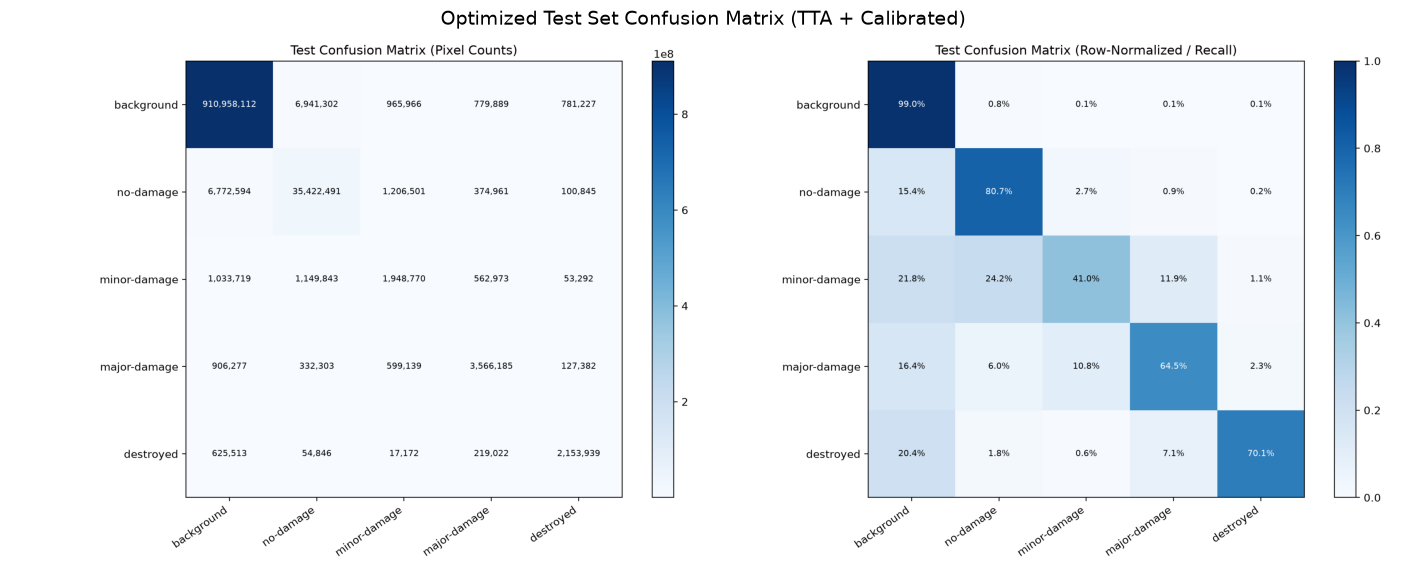

In [21]:
# ============================================================
# 6. CONFUSION MATRIX VISUALIZATION
# ============================================================

cm_path = OUTPUT_ROOT / "test_confusion_matrix_tta.png"
plot_confusion_matrix(confusion_tta, cm_path)

from PIL import Image
plt.figure(figsize=(18, 7))
plt.imshow(Image.open(cm_path))
plt.axis("off")
plt.title("Optimized Test Set Confusion Matrix (TTA + Calibrated)", fontsize=14)
plt.show()



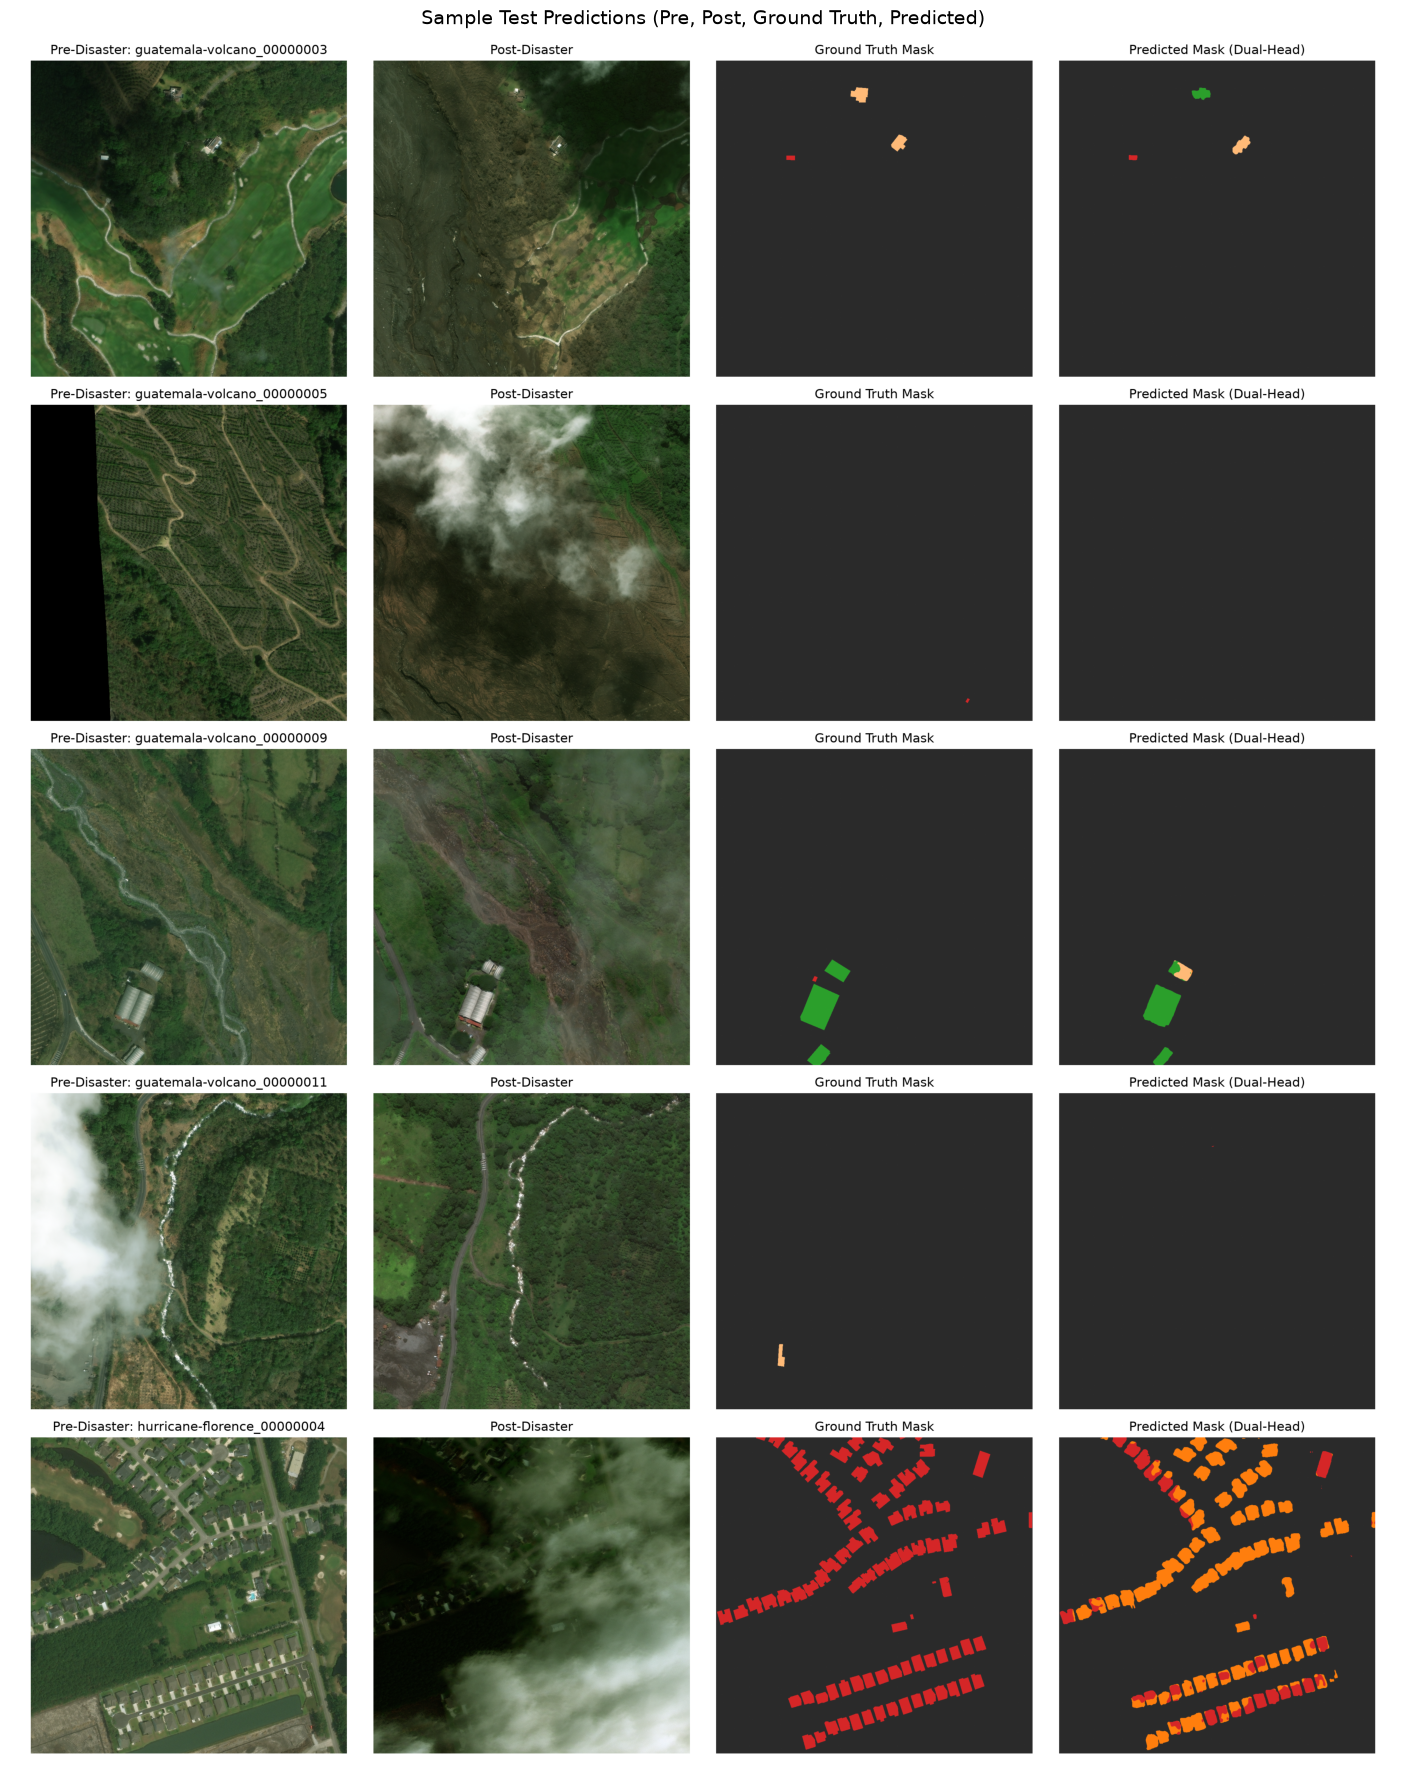

In [22]:
# ============================================================
# 7. QUALITATIVE VISUAL PREDICTIONS
# ============================================================

if visual_samples:
    vis_path = OUTPUT_ROOT / "test_predictions_visual.png"
    plot_visual_samples(visual_samples, vis_path)

    from PIL import Image
    plt.figure(figsize=(18, 4.5 * len(visual_samples)))
    plt.imshow(Image.open(vis_path))
    plt.axis("off")
    plt.title("Sample Test Predictions (Pre, Post, Ground Truth, Predicted)", fontsize=14)
    plt.show()

